In [5]:
import numpy as np
import matplotlib.pyplot as plt
print("Ready!")

Ready!


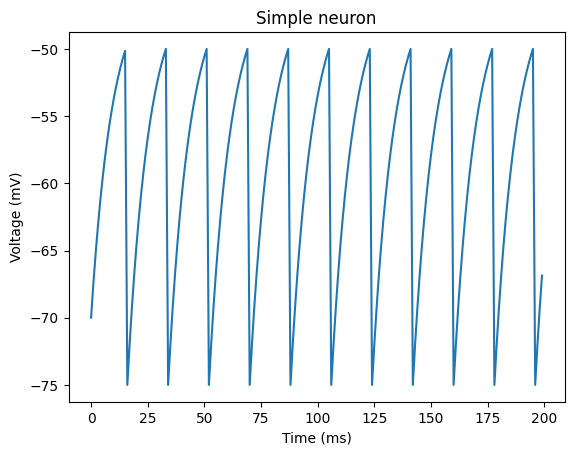

Number of spikes: 11


In [6]:
# Settings
dt = 1.0          # time step (ms)
T = 200           # total time (ms)
time = np.arange(0, T, dt)

v_rest = -70      # resting voltage (mV)
v_thresh = -50    # the neuron fires at this voltage
v_reset = -75     # voltage right after firing
tau = 10          # how fast the voltage leaks back (ms)
R = 10            # resistance
I = 2.5           # input current

v = np.zeros(len(time))
v[0] = v_rest
spikes = []

for t in range(1, len(time)):
    dv = (-(v[t-1] - v_rest) + R * I) / tau
    v[t] = v[t-1] + dv * dt
    if v[t] >= v_thresh:
        v[t] = v_reset
        spikes.append(time[t])

plt.plot(time, v)
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (mV)")
plt.title("Simple neuron")
plt.show()
print("Number of spikes:", len(spikes))

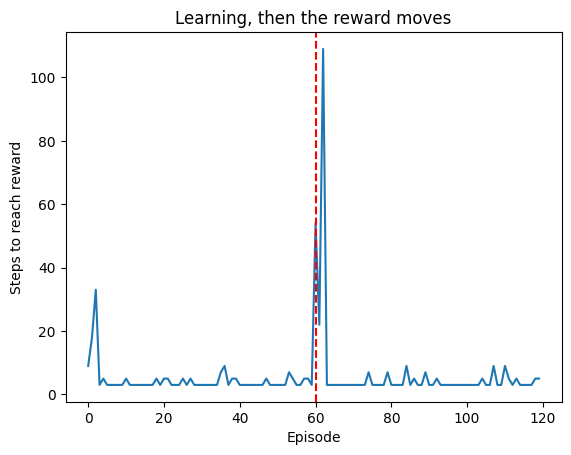

In [7]:
rng = np.random.default_rng(0)

n_states = 7
alpha, gamma, eps = 0.5, 0.9, 0.2   # learning speed, future value, random exploration

def run(Q, goal, episodes=60):
    steps_list = []
    for ep in range(episodes):
        s = 3                         # start in the middle
        steps = 0
        while s != goal and steps < 200:
            if rng.random() < eps:    # sometimes explore randomly
                a = rng.integers(2)
            else:                     # otherwise pick the best known move
                a = np.argmax(Q[s]) if Q[s, 0] != Q[s, 1] else rng.integers(2)
            s2 = min(max(s + (1 if a == 1 else -1), 0), n_states - 1)
            r = 1.0 if s2 == goal else 0.0
            Q[s, a] += alpha * (r + gamma * np.max(Q[s2]) - Q[s, a])
            s = s2
            steps += 1
        steps_list.append(steps)
    return steps_list

Q = np.zeros((n_states, 2))
phase1 = run(Q, goal=6)   # reward on the right
phase2 = run(Q, goal=0)   # reward moved to the left

plt.plot(phase1 + phase2)
plt.axvline(60, color="red", linestyle="--")
plt.xlabel("Episode")
plt.ylabel("Steps to reach reward")
plt.title("Learning, then the reward moves")
plt.show()